<a href="https://colab.research.google.com/github/yeminaung-web/AI_STUDY/blob/main/UCI_HAR/UCI_HAR(CNN%2CTransformer%5BVAE%5D%2CSE_ResNet).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
UCI-HAR Classification using CNN + LSTM
TensorFlow / Keras

Input:
    UCI-HAR Inertial Signals
    Shape = (samples, 128, 9)

Channels:
    body_acc_x
    body_acc_y
    body_acc_z
    body_gyro_x
    body_gyro_y
    body_gyro_z
    total_acc_x
    total_acc_y
    total_acc_z

Classes:
    0: WALKING
    1: WALKING_UPSTAIRS
    2: WALKING_DOWNSTAIRS
    3: SITTING
    4: STANDING
    5: LAYING
"""


'\nUCI-HAR Classification using CNN + LSTM\nTensorFlow / Keras\n\nInput:\n    UCI-HAR Inertial Signals\n    Shape = (samples, 128, 9)\n\nChannels:\n    body_acc_x\n    body_acc_y\n    body_acc_z\n    body_gyro_x\n    body_gyro_y\n    body_gyro_z\n    total_acc_x\n    total_acc_y\n    total_acc_z\n\nClasses:\n    0: WALKING\n    1: WALKING_UPSTAIRS\n    2: WALKING_DOWNSTAIRS\n    3: SITTING\n    4: STANDING\n    5: LAYING\n'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

# ============================================================
# 1. CONFIGURATION
# ============================================================

DATASET_PATH = "/content/drive/MyDrive/Colab Notebooks/human+activity+recognition+using+smartphones/UCI HAR Dataset"

SEED = 42
VALIDATION_RATIO = 0.20

BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 0.001

MODEL_PATH = "best_vae_se_resnet_transformer_uci_har.keras"




In [ ]:

# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Layer,
    Input,
    Conv1D,
    Conv1DTranspose,
    MaxPooling1D,
    BatchNormalization,
    Dense,
    Dropout,
    Activation,
    GlobalAveragePooling1D,
    Reshape,
    Multiply,
    Add,
    MultiHeadAttention,
    LayerNormalization
)




from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)



In [ ]:

# ============================================================
# 3. RANDOM SEED
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


print("=" * 70)
print("TensorFlow version:", tf.__version__)
print("=" * 70)



TensorFlow version: 2.21.0


In [ ]:

# ============================================================
# 4. SIGNAL / CLASS NAMES
# ============================================================

SIGNAL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",

    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",

    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]


CLASS_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]



In [ ]:

# ============================================================
# 5. LOAD INERTIAL SIGNALS
# ============================================================

def load_inertial_signals(dataset_path, split):

    """
    Load 9-channel UCI-HAR inertial signals.

    Each signal file:
        shape = (N, 128)

    After stacking:
        shape = (N, 128, 9)
    """

    signal_folder = os.path.join(
        dataset_path,
        split,
        "Inertial Signals"
    )

    signals = []

    for signal_name in SIGNAL_NAMES:

        filename = f"{signal_name}_{split}.txt"

        file_path = os.path.join(
            signal_folder,
            filename
        )

        if not os.path.exists(file_path):
            raise FileNotFoundError(
                f"File not found: {file_path}"
            )

        signal = np.loadtxt(
            file_path,
            dtype=np.float32
        )

        print(
            f"{split:5s} | "
            f"{signal_name:20s} | "
            f"{signal.shape}"
        )

        signals.append(signal)

    # (N, 128, 9)
    X = np.stack(
        signals,
        axis=-1
    )

    return X


In [ ]:


# ============================================================
# 6. LOAD LABELS
# ============================================================

def load_labels(dataset_path, split):

    label_path = os.path.join(
        dataset_path,
        split,
        f"y_{split}.txt"
    )

    y = np.loadtxt(
        label_path,
        dtype=np.int32
    )

    # Original UCI-HAR labels:
    # 1 ~ 6
    #
    # TensorFlow:
    # 0 ~ 5

    y = y - 1

    return y



In [ ]:

# ============================================================
# 7. LOAD TRAIN / TEST DATA
# ============================================================

print("\nLoading training data...\n")

X_train_full = load_inertial_signals(
    DATASET_PATH,
    "train"
)

y_train_full = load_labels(
    DATASET_PATH,
    "train"
)


print("\nLoading test data...\n")

X_test = load_inertial_signals(
    DATASET_PATH,
    "test"
)

y_test = load_labels(
    DATASET_PATH,
    "test"
)


print("\n" + "=" * 70)
print("Original dataset")
print("=" * 70)

print(
    "X_train_full:",
    X_train_full.shape
)

print(
    "y_train_full:",
    y_train_full.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)




Loading training data...

train | body_acc_x           | (7352, 128)
train | body_acc_y           | (7352, 128)
train | body_acc_z           | (7352, 128)
train | body_gyro_x          | (7352, 128)
train | body_gyro_y          | (7352, 128)
train | body_gyro_z          | (7352, 128)
train | total_acc_x          | (7352, 128)
train | total_acc_y          | (7352, 128)
train | total_acc_z          | (7352, 128)

Loading test data...

test  | body_acc_x           | (2947, 128)
test  | body_acc_y           | (2947, 128)
test  | body_acc_z           | (2947, 128)
test  | body_gyro_x          | (2947, 128)
test  | body_gyro_y          | (2947, 128)
test  | body_gyro_z          | (2947, 128)
test  | total_acc_x          | (2947, 128)
test  | total_acc_y          | (2947, 128)
test  | total_acc_z          | (2947, 128)

Original dataset
X_train_full: (7352, 128, 9)
y_train_full: (7352,)
X_test: (2947, 128, 9)
y_test: (2947,)


In [ ]:

# ============================================================
# 8. TRAIN / VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(

    X_train_full,
    y_train_full,

    test_size=VALIDATION_RATIO,

    random_state=SEED,

    stratify=y_train_full
)


print("\n" + "=" * 70)
print("Dataset split")
print("=" * 70)

print(
    "Train:",
    X_train.shape
)

print(
    "Validation:",
    X_val.shape
)

print(
    "Test:",
    X_test.shape
)




Dataset split
Train: (5881, 128, 9)
Validation: (1471, 128, 9)
Test: (2947, 128, 9)


In [ ]:

# ============================================================
# 9. STANDARD SCALER
# ============================================================

"""
Original shape:

    (samples, 128, 9)

StandardScaler requires:

    (observations, features)

Therefore reshape:

    (samples * 128, 9)

The 9 sensor channels are standardized independently.

IMPORTANT:
    scaler.fit() is performed ONLY on training data.
"""


num_channels = X_train.shape[-1]

scaler = StandardScaler()


# ------------------------------------------------------------
# Fit scaler using training data only
# ------------------------------------------------------------

X_train_2d = X_train.reshape(
    -1,
    num_channels
)

scaler.fit(
    X_train_2d
)


# ------------------------------------------------------------
# Transform function
# ------------------------------------------------------------

def standardize_data(X, scaler):

    original_shape = X.shape

    X_2d = X.reshape(
        -1,
        original_shape[-1]
    )

    X_scaled = scaler.transform(
        X_2d
    )

    X_scaled = X_scaled.reshape(
        original_shape
    )

    return X_scaled.astype(
        np.float32
    )


# ------------------------------------------------------------
# Apply StandardScaler
# ------------------------------------------------------------

X_train = standardize_data(
    X_train,
    scaler
)

X_val = standardize_data(
    X_val,
    scaler
)

X_test = standardize_data(
    X_test,
    scaler
)


print("\n" + "=" * 70)
print("StandardScaler")
print("=" * 70)

print(
    "Training channel means:"
)

print(
    np.round(
        np.mean(
            X_train,
            axis=(0, 1)
        ),
        4
    )
)

print(
    "\nTraining channel standard deviations:"
)

print(
    np.round(
        np.std(
            X_train,
            axis=(0, 1)
        ),
        4
    )
)




StandardScaler
Training channel means:
[ 0.  0.  0.  0.  0. -0.  0. -0.  0.]

Training channel standard deviations:
[0.9997 0.9995 0.9994 0.9997 0.9996 0.9996 0.9997 0.9998 0.9998]


In [ ]:
# ============================================================
# 10A. UNSUPERVISED VAE PRE-TRAINING (SE-ResNet Encoder)
# ============================================================

def se_resnet_block(x, filters, kernel_size=5, reduction=8):
    shortcut = x

    # ResNet Main Conv Path
    out = Conv1D(filters=filters, kernel_size=kernel_size, padding="same", use_bias=False)(x)
    out = BatchNormalization()(out)
    out = Activation("relu")(out)

    out = Conv1D(filters=filters, kernel_size=kernel_size, padding="same", use_bias=False)(out)
    out = BatchNormalization()(out)

    # Squeeze-and-Excitation (SE) Channel Attention
    se = GlobalAveragePooling1D()(out)
    se = Dense(filters // reduction, activation="relu")(se)
    se = Dense(filters, activation="sigmoid")(se)
    se = Reshape((1, filters))(se)
    out = Multiply()([out, se])

    # ResNet Skip Connection
    if shortcut.shape[-1] != filters:
        shortcut = Conv1D(filters=filters, kernel_size=1, padding="same", use_bias=False)(shortcut)
        shortcut = BatchNormalization()(shortcut)

    out = Add()([out, shortcut])
    out = Activation("relu")(out)
    return out


class Sampling(Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


class ConvVAE(Model):
    def __init__(self, encoder, decoder, beta=0.01, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.recon_loss_tracker = tf.keras.metrics.Mean(name="recon_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.recon_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data, training=True)
            reconstruction = self.decoder(z, training=True)
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(tf.square(data - reconstruction), axis=(1, 2))
            )
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                    axis=1
                )
            )
            total_loss = recon_loss + self.beta * kl_loss

        grads = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }


def build_vae(latent_dim=64):
    # Encoder
    enc_inputs = Input(shape=(128, 9))
    x = se_resnet_block(enc_inputs, filters=64, kernel_size=5)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.30)(x)

    x = se_resnet_block(x, filters=128, kernel_size=5)
    features = MaxPooling1D(pool_size=2, name="se_resnet_features")(x)

    h = GlobalAveragePooling1D()(features)
    z_mean = Dense(latent_dim, name="z_mean")(h)
    z_log_var = Dense(latent_dim, name="z_log_var")(h)
    z = Sampling()([z_mean, z_log_var])
    encoder = Model(enc_inputs, [z_mean, z_log_var, z], name="se_resnet_encoder")

    # Decoder
    dec_inputs = Input(shape=(latent_dim,))
    d = Dense(32 * 128, activation="relu")(dec_inputs)
    d = Reshape((32, 128))(d)
    d = Conv1DTranspose(filters=128, kernel_size=5, strides=2, padding="same", activation="relu")(d)
    d = Conv1DTranspose(filters=64, kernel_size=5, strides=2, padding="same", activation="relu")(d)
    dec_outputs = Conv1D(filters=9, kernel_size=3, padding="same")(d)
    decoder = Model(dec_inputs, dec_outputs, name="se_resnet_decoder")

    vae = ConvVAE(encoder, decoder, beta=0.01)
    return vae, encoder, decoder


vae, encoder, decoder = build_vae(latent_dim=64)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE))
vae_history = vae.fit(X_train, epochs=25, batch_size=BATCH_SIZE, verbose=1)


Epoch 1/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 30s 247ms/step - kl_loss: 75.8415 - loss: 917.0871 - recon_loss: 916.3285
Epoch 2/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 33s 355ms/step - kl_loss: 98.4636 - loss: 814.1052 - recon_loss: 813.1207
Epoch 3/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 30s 240ms/step - kl_loss: 110.5850 - loss: 796.3669 - recon_loss: 795.2612
Epoch 4/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 245ms/step - kl_loss: 113.5320 - loss: 791.4554 - recon_loss: 790.3199
Epoch 5/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 42s 260ms/step - kl_loss: 116.6409 - loss: 787.5167 - recon_loss: 786.3503
Epoch 6/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 40s 246ms/step - kl_loss: 120.2117 - loss: 782.1246 - recon_loss: 780.9224
Epoch 7/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 245ms/step - kl_loss: 125.7592 - loss: 775.9431 - recon_loss: 774.6855
Epoch 8/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 231ms/step - kl_loss: 134.3606 - loss: 765.3770 - recon_loss: 764.0334
Epoch 9/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 41s 230ms/step - kl_loss: 145.3170 - loss: 750.7366 - recon_

In [ ]:
# ============================================================
# 10B. SE-ResNet + TRANSFORMER CLASSIFIER ARCHITECTURE
# ============================================================

def transformer_encoder_block(x, d_model=128, num_heads=4, ff_dim=128, dropout=0.30):
    # Positional Encoding
    pos = Conv1D(filters=d_model, kernel_size=3, padding="same")(x)
    x = Add()([x, pos])

    # Multi-Head Self-Attention + Residual
    attn_in = LayerNormalization(epsilon=1e-6)(x)
    attn_out = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout
    )(attn_in, attn_in)
    attn_out = Dropout(dropout)(attn_out)
    x = Add()([x, attn_out])

    # Feed-Forward Network + Residual
    ffn_in = LayerNormalization(epsilon=1e-6)(x)
    ffn_out = Dense(units=ff_dim, activation="relu")(ffn_in)
    ffn_out = Dropout(dropout)(ffn_out)
    ffn_out = Dense(units=d_model)(ffn_out)
    ffn_out = Dropout(dropout)(ffn_out)
    x = Add()([x, ffn_out])

    x = LayerNormalization(epsilon=1e-6)(x)
    return x


def build_model(pretrained_encoder):
    pretrained_features = pretrained_encoder.get_layer("se_resnet_features").output

    x = Dropout(0.30)(pretrained_features)
    x = transformer_encoder_block(x, d_model=128, num_heads=4, ff_dim=128, dropout=0.30)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.30)(x)

    x = Dense(units=64, activation="relu")(x)
    x = Dropout(0.30)(x)
    outputs = Dense(units=6, activation="softmax")(x)

    classifier = Model(
        inputs=pretrained_encoder.input,
        outputs=outputs,
        name="VAE_SE_ResNet_Transformer"
    )
    return classifier


model = build_model(encoder)


In [ ]:

# ============================================================
# 11. COMPILE
# ============================================================

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)


model.compile(

    optimizer=optimizer,

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)


print("\n")
model.summary()


Model: "VAE_SE_ResNet_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 9)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 128, 64)   │      2,880 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 64)   │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 64)   │     20,480 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8)         │        520 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │        576 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 64)     │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 128, 64)   │        576 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 128, 64)   │          0 │ batch_normalizat… │
│                     │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 64)   │          0 │ multiply[0][0],   │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 64)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 64, 64)    │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 64)    │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 64, 128)   │     40,960 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128)   │        512 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 320,414 (1.22 MB)

 Trainable params: 319,262 (1.22 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [ ]:


# ============================================================
# 12. CALLBACKS
# ============================================================

callbacks = [

    EarlyStopping(

        monitor="val_loss",

        patience=15,

        restore_best_weights=True,

        verbose=1
    ),


    ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=5,

        min_lr=1e-6,

        verbose=1
    ),


    ModelCheckpoint(

        filepath=MODEL_PATH,

        monitor="val_loss",

        save_best_only=True,

        verbose=1
    )
]



In [ ]:

# ============================================================
# 13. TRAIN
# ============================================================

print("\n" + "=" * 70)
print("Training SE-ResNet + Transformer VAE")
print("=" * 70)


history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=callbacks,

    verbose=1
)




Training SE-ResNet + Transformer VAE
Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - accuracy: 0.7152 - loss: 0.7000
Epoch 1: val_loss improved from None to 0.13049, saving model to best_vae_se_resnet_transformer_uci_har.keras

Epoch 1: finished saving model to best_vae_se_resnet_transformer_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 42s 354ms/step - accuracy: 0.8487 - loss: 0.3820 - val_accuracy: 0.9613 - val_loss: 0.1305 - learning_rate: 0.0010
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - accuracy: 0.9422 - loss: 0.1583
Epoch 2: val_loss improved from 0.13049 to 0.12347, saving model to best_vae_se_resnet_transformer_uci_har.keras

Epoch 2: finished saving model to best_vae_se_resnet_transformer_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 32s 343ms/step - accuracy: 0.9415 - loss: 0.1497 - val_accuracy: 0.9551 - val_loss: 0.1235 - learning_rate: 0.0010
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - accuracy: 0.9441 - loss: 0.1369
Epoch 3: val_loss improved from 0.

In [ ]:

# ============================================================
# 14. LOAD BEST MODEL
# ============================================================

model = tf.keras.models.load_model(
    MODEL_PATH
)



In [ ]:

# ============================================================
# 15. TEST PREDICTION
# ============================================================

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=BATCH_SIZE,

    verbose=0
)


y_prob = model.predict(

    X_test,

    batch_size=BATCH_SIZE,

    verbose=0
)


y_pred = np.argmax(
    y_prob,
    axis=1
)



In [ ]:

# ============================================================
# 16. PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)


macro_precision = precision_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


macro_recall = recall_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


macro_f1 = f1_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


weighted_f1 = f1_score(

    y_test,
    y_pred,

    average="weighted",

    zero_division=0
)


print("\n" + "=" * 70)
print("TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss        : {test_loss:.4f}"
)

print(
    f"Accuracy         : {accuracy:.4f}"
)

print(
    f"Macro Precision  : {macro_precision:.4f}"
)

print(
    f"Macro Recall     : {macro_recall:.4f}"
)

print(
    f"Macro F1         : {macro_f1:.4f}"
)

print(
    f"Weighted F1      : {weighted_f1:.4f}"
)




TEST RESULTS
Test Loss        : 0.4845
Accuracy         : 0.9369
Macro Precision  : 0.9372
Macro Recall     : 0.9378
Macro F1         : 0.9375
Weighted F1      : 0.9369


In [ ]:

# ============================================================
# 17. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)


print(

    classification_report(

        y_test,
        y_pred,

        target_names=CLASS_NAMES,

        digits=4,

        zero_division=0
    )
)




CLASSIFICATION REPORT
                    precision    recall  f1-score   support

           WALKING     0.9899    0.9859    0.9879       496
  WALKING_UPSTAIRS     0.9696    0.9490    0.9592       471
WALKING_DOWNSTAIRS     0.9447    0.9762    0.9602       420
           SITTING     0.8525    0.8473    0.8498       491
          STANDING     0.8668    0.8684    0.8676       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9369      2947
         macro avg     0.9372    0.9378    0.9375      2947
      weighted avg     0.9369    0.9369    0.9369      2947



In [ ]:

# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)


print("\nConfusion Matrix")

print(cm)




Confusion Matrix
[[489   1   6   0   0   0]
 [  4 447  18   2   0   0]
 [  1   9 410   0   0   0]
 [  0   4   0 416  71   0]
 [  0   0   0  70 462   0]
 [  0   0   0   0   0 537]]


In [ ]:

# ============================================================
# 19. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = (

    cm.astype(np.float32)

    / np.maximum(
        cm.sum(
            axis=1,
            keepdims=True
        ),
        1
    )
)


print("\nNormalized Confusion Matrix")

print(
    np.round(
        cm_normalized,
        4
    )
)




Normalized Confusion Matrix
[[0.9859 0.002  0.0121 0.     0.     0.    ]
 [0.0085 0.949  0.0382 0.0042 0.     0.    ]
 [0.0024 0.0214 0.9762 0.     0.     0.    ]
 [0.     0.0081 0.     0.8473 0.1446 0.    ]
 [0.     0.     0.     0.1316 0.8684 0.    ]
 [0.     0.     0.     0.     0.     1.    ]]


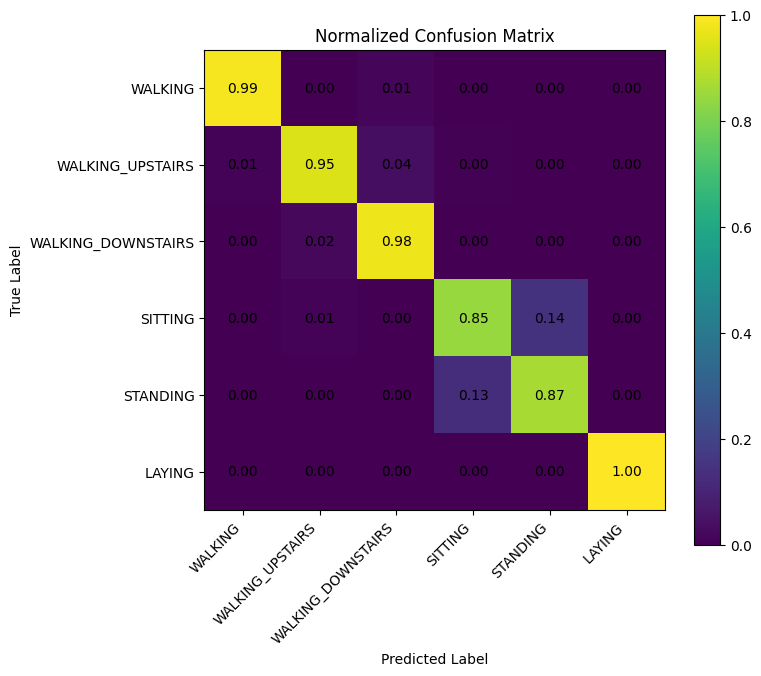

In [ ]:

# ============================================================
# 20. PLOT CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(8, 7)
)


plt.imshow(
    cm_normalized
)


plt.colorbar()


plt.xticks(

    np.arange(
        len(CLASS_NAMES)
    ),

    CLASS_NAMES,

    rotation=45,

    ha="right"
)


plt.yticks(

    np.arange(
        len(CLASS_NAMES)
    ),

    CLASS_NAMES
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Normalized Confusion Matrix"
)


for i in range(
    len(CLASS_NAMES)
):

    for j in range(
        len(CLASS_NAMES)
    ):

        plt.text(

            j,
            i,

            f"{cm_normalized[i, j]:.2f}",

            ha="center",

            va="center"
        )


plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


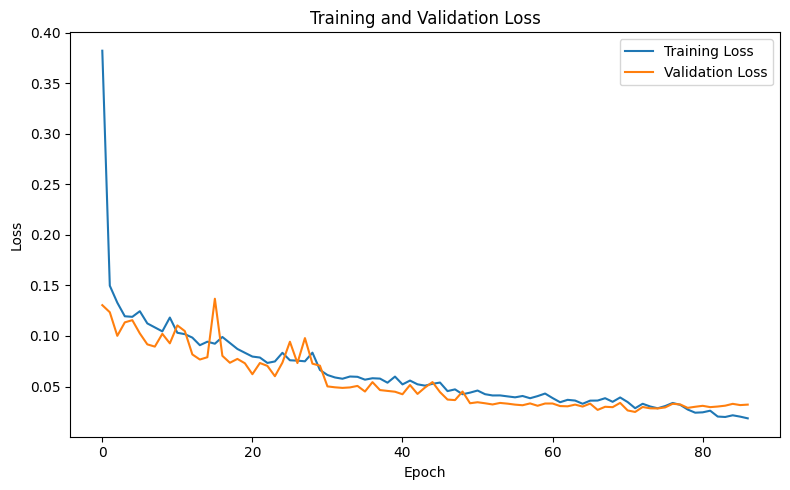

In [ ]:


# ============================================================
# 21. TRAINING LOSS
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history["loss"],
    label="Training Loss"
)


plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.show()



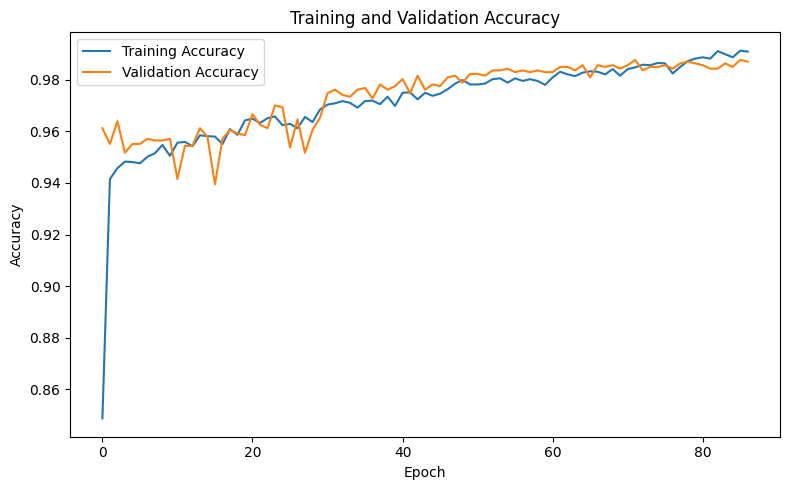


Finished.


In [ ]:

# ============================================================
# 22. TRAINING ACCURACY
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)


plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()

plt.tight_layout()

plt.show()


print("\nFinished.")